# 응용 모의 제1회 풀이

공동주택 가격과 계약 심사

공식 정답이 아닌 실제 실행 예시 답안입니다. PDF와 지문이 동일합니다. 각 문항의 가정·가설·실제 수치·판단을 함께 읽고 src 모듈 및 공통 analysis.py를 참조하십시오.

In [1]:
from pathlib import Path
import sys
FOLDER=Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
sys.path.insert(0,str(FOLDER.parent/'공통'))
from analysis import Context
ctx=Context(FOLDER)


## 1. 회귀 설계와 조건별 개선

면적·연식·거리·방 수가 가격에 주는 관계를 설명한다. 면적과 방 수에 중복 정보가 있으며 입력 결측이 있다. 변환이 설명력을 높인다는 전제 없이 검증한다. regression.csv의240행은 서로 독립인 개체/배치을 가정한 고정 합성 자료다. 목표 target의 단위는 가격(천만원)이며 id는 식별자다. 입력은 area, building_age, station_distance, rooms다. 입력은 고정 업무 기준 대비 편차 지수이므로 음수가 가능하며 표본 전체에서 미리 추정한 표준화 값이 아니다. 시드20270001로 학습70%/최종평가30% 분할하고 학습 shuffled3-fold를 사용한다. 후보 선택 기준은 동일 원반응 단위 CV R² 최대다. 기본 대치·표준화·선형 모형, VIF5, AIC/BIC 후진 선택과 특성의 Yeo-Johnson 변환 후보를 사전 지정한다. 모든 학습 통계·변수선택·행 처리는 폴드 안에서 적합한다. 유의수준은5%이며 반복 진단은 탐색적 개별검정으로 보고한다. 최종평가로 후보나 가정을 골라서는 안 된다.

### 1-1

**문제 (6점)** 관측 단위·목표 척도·예측 시점과 입력의 역할을 정리하고 결측·분포·공선성 후보를 탐색하시오. 지정 분할의 원행 위치를 남기고 전체 자료 대치나 식별자 입력이 왜 부적절한지 설명하시오.

**선택 근거·가정·해석**

원행 위치를 먼저 봉인하고 결측 대치·스케일·선택은 Pipeline.fit 안에 둔다. id는 의미 없는 식별자이며 test는 최종 보고만 한다.

In [2]:
ctx.run('1-1','reg_design')

{'n': 240,
 'feature_names': ['area', 'building_age', 'station_distance', 'rooms'],
 'missing': {'area': 0, 'building_age': 8, 'station_distance': 0, 'rooms': 0},
 'train_indices': [1,
  4,
  5,
  7,
  8,
  10,
  12,
  15,
  17,
  18,
  19,
  20,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  36,
  40,
  41,
  42,
  43,
  44,
  45,
  46,
  48,
  49,
  51,
  53,
  56,
  57,
  60,
  61,
  62,
  65,
  67,
  68,
  69,
  70,
  71,
  72,
  73,
  74,
  78,
  79,
  80,
  82,
  83,
  84,
  86,
  88,
  89,
  92,
  93,
  94,
  96,
  97,
  99,
  100,
  101,
  102,
  103,
  104,
  105,
  107,
  108,
  109,
  111,
  113,
  114,
  115,
  116,
  117,
  118,
  120,
  121,
  122,
  123,
  127,
  128,
  130,
  131,
  132,
  134,
  135,
  136,
  137,
  138,
  139,
  140,
  141,
  142,
  143,
  144,
  145,
  146,
  147,
  148,
  152,
  154,
  157,
  158,
  159,
  160,
  162,
  163,
  164,
  165,
  166,
  168,
  169,
  170,
  172,
  173,
  175,
  177,
  178,
  179,
  180,
  182,
  183,


### 1-2

**문제 (6점)** 기본 전처리와 선형 기준 모형을 학습에 적합하고 학습/CV R², 계수 t 검정·전체 F 검정·AIC·BIC를 제시하시오. 계수·설명력·일반화 성능의 의미와 기본 추론 가정을 구분하시오. 최종평가는 아직 사용하지 마시오.

**선택 근거·가정·해석**

R²와 수정 R²는 적합 설명력, CV R²는 학습 밖 예측 평가다. t는 개별 계수, F는 지정 전체 기울기 가설이다. 고전적 추론은 올바른 사양·독립·등분산·정규 오차에 조건부이며 y 자체 정규성을 요구하지 않는다.

In [3]:
ctx.run('1-2','reg_baseline')

{'train': {'r2': 0.9519806427709984,
  'rmse': 0.4631324534927108,
  'mae': 0.3693184645159269},
 'cv_r2': 0.9468951543744181,
 'coefficients': {'columns': ['term',
   'coefficient',
   'standard_error',
   't_statistic',
   'p_value',
   'ci_lower',
   'ci_upper',
   'reject_h0'],
  'index': [0, 1, 2, 3, 4],
  'data': [['Intercept',
    19.93404085304524,
    0.03627533339267273,
    549.5205416105624,
    2.832072572624984e-268,
    19.862410686594306,
    20.005671019496173,
    True],
   ['numeric__area',
    2.429020740414705,
    0.29977479027098775,
    8.10281857997112,
    1.2016716206838177e-13,
    1.8370780588005855,
    3.0209634220288244,
    True],
   ['numeric__building_age',
    -0.3932023709260598,
    0.03651552514701153,
    -10.768087528332861,
    9.222630244019126e-21,
    -0.4653068259288651,
    -0.32109791592325454,
    True],
   ['numeric__station_distance',
    -0.36499742423243386,
    0.30002630662366275,
    -1.2165514029083706,
    0.22553359136993803,
 

### 1-3

**문제 (6점)** 기준 모형의 선형 사양·잔차 정규성·등분산성과 관측 설계에 맞는 독립성/자기상관을 진단하시오. 가설·통계량·p값·가정·판정과 잔차/분위수/영향도 그림을 보고하시오. VIF와 Cook 영향도의 대상을 구분하고 이상 관측을 자동으로 오류라고 단정하지 마시오.

**선택 근거·가정·해석**

정규성은 적합 잔차의 JB, 사양은 RESET, 등분산은 Koenker/BP를 사용한다. IID의 DW는 기술값만, 명시 시간순은 BG를 사용한다. 가설을 각각 분리하고 탐색적 개별 p값을 해석한다. VIF는 설계 열, Cook은 관측의 추정 영향이며 비기각은 가정 증명이 아니다.

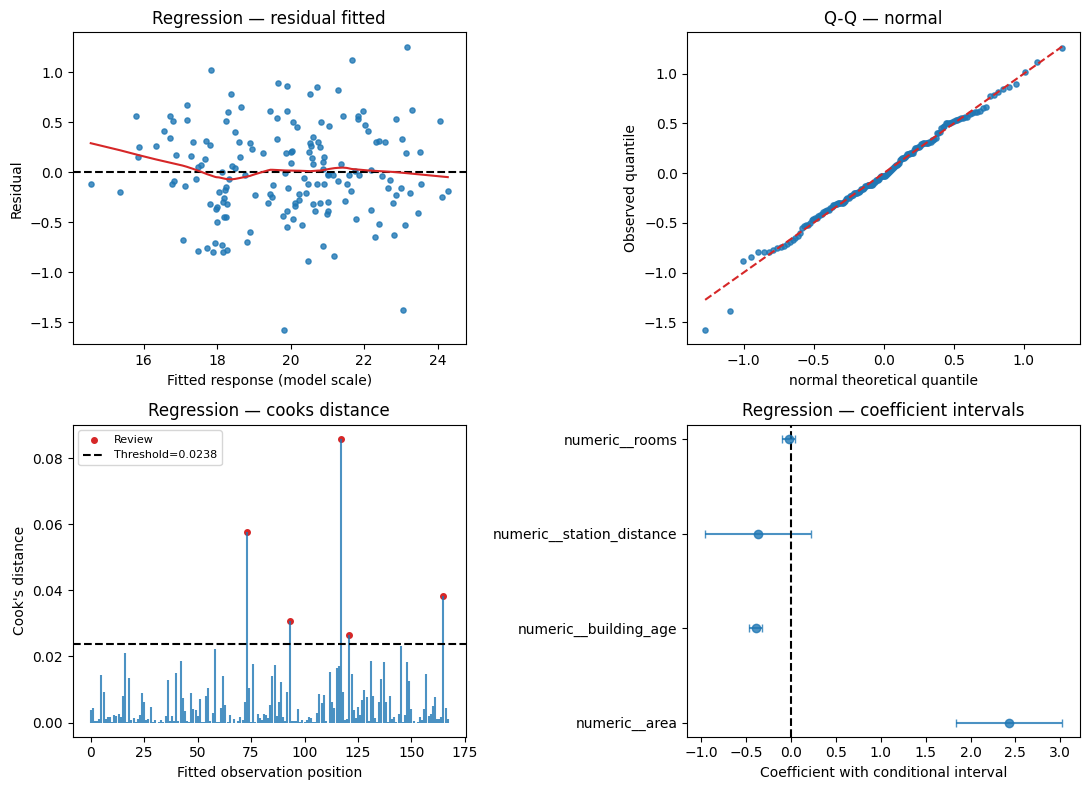

{'tests': {'normality': {'tests': {'columns': ['test',
     'statistic',
     'p_value',
     'reject_h0',
     'df_num',
     'df_den'],
    'index': [0],
    'data': [['jarque_bera',
      1.448946410423203,
      0.48457977582910494,
      False,
      None,
      None]]},
   'details': {'n_samples': 168, 'hypothesis': '정규 오차'},
   'parameters': {'alpha': 0.05, 'method': 'jarque_bera'},
   'warnings': ['반응변수 y가 아닌 잔차를 검사합니다. 적합 잔차의 의존성 때문에 iid 표본 검정의 p를 단독 확정 기준으로 쓰지 않습니다.']},
  'linearity': {'tests': {'columns': ['test',
     'statistic',
     'p_value',
     'reject_h0',
     'df_num',
     'df_den'],
    'index': [0],
    'data': [['RESET F',
      0.5507876172918849,
      0.5775779304296117,
      False,
      2.0,
      161.0]]},
   'details': {'n_samples': 168, 'hypothesis': '해당 대안 대비 선형 사양이 적절함'},
   'parameters': {'alpha': 0.05,
    'method': 'reset',
    'power': 3,
    'fraction': 0.5},
   'warnings': ['비기각은 선형성의 증명이 아닙니다. RESET는 누락변수/함수형 등 다른 사양 오류에도 반응하고 Rainbow는 행 순서·등

In [4]:
ctx.run('1-3','reg_diagnostics')

### 1-4

**문제 (6점)** 동일 학습 행·동일 원반응에서 AIC와 BIC로 후진 변수선택을 수행하고 제거 경로·남은 특성을 비교하시오. VIF 제거와의 차이, 서로 다른 y변환·관측 행의 정보량을 직접 비교하는 오류, 변수선택 후 추론의 한계를 설명하시오.

**선택 근거·가정·해석**

AIC=-2ll+2k, BIC=-2ll+log(n)k의 감소를 따라 탐욕적 후진 선택한다. 같은 행/반응의 비교다. 최적 부분집합 보장이나 선택 후 추론 보정은 없으며 CV 폴드에서 다시 선택해야 한다.

In [5]:
ctx.run('1-4','reg_selection')

{'aic': {'selected_features': ['numeric__area', 'numeric__building_age'],
  'history': {'columns': ['step', 'removed', 'aic', 'bic', 'accepted'],
   'index': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
   'data': [[0, None, 228.12997160240195, 243.74979149941825, True],
    [1, 'numeric__area', 282.99243467175904, 295.48829058937207, False],
    [1, 'numeric__building_age', 316.3944362551585, 328.8902921727715, False],
    [1,
     'numeric__station_distance',
     227.64848414616512,
     240.14434006377815,
     False],
    [1, 'numeric__rooms', 226.64111153653283, 239.13696745414586, True],
    [2, 'numeric__area', 281.6620362262279, 291.03392816443767, False],
    [2, 'numeric__building_age', 314.3956360857076, 323.7675280239174, False],
    [2,
     'numeric__station_distance',
     226.25262434300413,
     235.62451628121391,
     True],
    [3, 'numeric__area', 730.8137583361764, 737.0616862949829, False],
    [3,
     'numeric__building_age',
     313.3452111700551,
     319.59313912886165

### 1-5

**문제 (6점)** 사전 지정 전처리·변수선택·대안 모형을 학습 CV 내부에서 튜닝하시오. 후보별 원단위 CV R²·선택 파라미터·실패 여부와 분할을 보고하고 하나를 선택하시오. 특히 특성의 Yeo-Johnson 변환 후보의 적용 조건과 처리 단위를 설명하시오.

**선택 근거·가정·해석**

원단위 CV R² 최대를 선택하며 후보별 clone은 각 학습 폴드에서 모든 처리를 새로 적합한다. 기준 대비 진단과 점수를 함께 보고 test로 모델을 바꾸지 않는다. 변환은 학습 폴드에서만 적합한다. 이미 같은 열공간인 OLS를 표준화하는 것만으로 R²가 증가하지 않는다. 변환 필요성은 CV와 진단을 함께 해석한다.

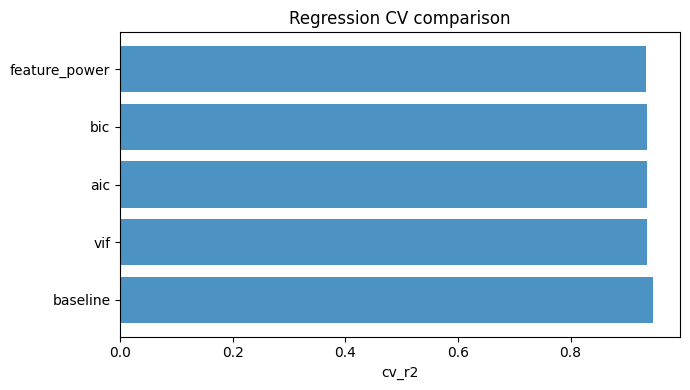

{'comparison': {'columns': ['name', 'cv_r2', 'best_params'],
  'index': [0, 1, 2, 3, 4],
  'data': [['baseline', 0.9468951543744181, {'degree': 1}],
   ['vif', 0.935903067442954, {'degree': 1}],
   ['aic', 0.9357637521359292, {'degree': 1}],
   ['bic', 0.9357637521359292, {'degree': 1}],
   ['feature_power', 0.9343829262245059, {'degree': 1}]]},
 'selected_name': 'baseline',
 'folds': [{'train_indices': [4,
    5,
    7,
    8,
    10,
    11,
    12,
    15,
    16,
    17,
    18,
    20,
    21,
    22,
    23,
    26,
    27,
    28,
    31,
    32,
    33,
    35,
    36,
    37,
    38,
    39,
    40,
    41,
    42,
    43,
    45,
    46,
    48,
    50,
    51,
    52,
    53,
    56,
    57,
    58,
    61,
    62,
    64,
    66,
    68,
    69,
    71,
    72,
    74,
    75,
    77,
    78,
    80,
    81,
    83,
    84,
    86,
    88,
    89,
    91,
    93,
    94,
    96,
    97,
    99,
    101,
    102,
    103,
    104,
    105,
    108,
    109,
    110,
    111,

In [6]:
ctx.run('1-5','reg_tuning')

### 1-6

**문제 (6점)** 선택 이후에만 기준/선택 모형을 동일 최종평가 행으로 평가하여 R²·RMSE·MAE와 R² 차이를 보고하시오. 진단 전후 또는 대안 분포의 적절한 잔차·분산·영향도 근거를 해석하고, 개선이 없거나 가정 위반이 남아도 그대로 보고하시오. 변환은 학습 폴드에서만 적합한다. 이미 같은 열공간인 OLS를 표준화하는 것만으로 R²가 증가하지 않는다. 변환 필요성은 CV와 진단을 함께 해석한다.

**선택 근거·가정·해석**

같은 보류 원행에서 기준/선택 점수를 계산하고 ΔR²=선택-기준을 그대로 보고한다. 개선이나 모든 가정 만족을 보장하지 않는다. 변환은 학습 폴드에서만 적합한다. 이미 같은 열공간인 OLS를 표준화하는 것만으로 R²가 증가하지 않는다. 변환 필요성은 CV와 진단을 함께 해석한다.

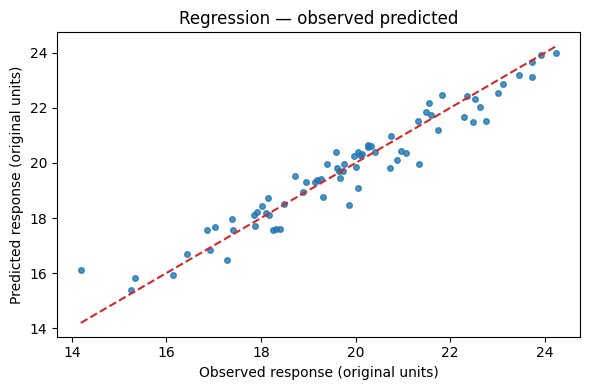

{'selected_name': 'baseline',
 'baseline_test': {'r2': 0.9320696349146045,
  'rmse': 0.574678194943402,
  'mae': 0.440918037911929},
 'selected_test': {'r2': 0.9320696349146045,
  'rmse': 0.574678194943402,
  'mae': 0.440918037911929},
 'delta_r2': 0.0,
 'test_indices': [0,
  2,
  3,
  6,
  9,
  11,
  13,
  14,
  16,
  21,
  33,
  34,
  35,
  37,
  38,
  39,
  47,
  50,
  52,
  54,
  55,
  58,
  59,
  63,
  64,
  66,
  75,
  76,
  77,
  81,
  85,
  87,
  90,
  91,
  95,
  98,
  106,
  110,
  112,
  119,
  124,
  125,
  126,
  129,
  133,
  149,
  150,
  151,
  153,
  155,
  156,
  161,
  167,
  171,
  174,
  176,
  181,
  185,
  186,
  188,
  190,
  193,
  196,
  197,
  199,
  202,
  212,
  219,
  220,
  230,
  237,
  239],
 'truth': [20.0575398088,
  22.6305878678,
  17.8488258982,
  19.8703710044,
  22.294437505,
  21.8335891202,
  18.1586030264,
  16.9139819195,
  18.1635391064,
  20.1387639055,
  20.2550962507,
  19.675676263,
  19.9758861578,
  23.7258922867,
  18.9608109113,
  18

In [7]:
ctx.run('1-6','reg_final')

## 2. 이진 사건 예측과 샘플링

classification.csv는 별도 독립360관측의 합성 자료이며 target=1은 연체 발생이다. c1~c4는 사건 발생 전의 수치 위험 신호, id는 식별자다. 층화 학습70%/최종평가30% 분할(시드20270001), 학습3-fold ROC AUC를 사용한다. 무보완과 random_over를 비교하되 학습 폴드 안의 대치→표준화→VIF5→샘플링→L2 로지스틱 예측모형을 사용한다. C 후보는0.1·1·10이고 GridSearchCV 전수비교로 튜닝한다. 운영 임계값0.5는 사전 고정이며 false-negative 비용4·false-positive 비용1이다. 별도로 원 학습 분포의 비벌점 이진 GLM을 설명용 적합하되 예측모형과 같은 추정량이라 주장하지 않는다.

### 2-1

**문제 (8점)** 목표 사건·양성 라벨·클래스 불균형과 층화 분할을 정리하시오. 데이터 분리 전에 샘플을 보완하면 발생하는 누출과 최종평가의 자연 발생률을 유지해야 하는 이유를 설명하시오.

**선택 근거·가정·해석**

층화 분할은 사건 비율을 보존한다. 샘플링은 imblearn Pipeline의 CV fit 내부이며 검증·test는 원 발생률 그대로다. 합성 표본은 원행을 갖는 실제 관측으로 보고하지 않는다.

In [8]:
ctx.run('2-1','cls_design')

{'train_indices': [0,
  1,
  3,
  4,
  5,
  6,
  9,
  10,
  12,
  13,
  14,
  15,
  16,
  18,
  19,
  20,
  21,
  23,
  26,
  28,
  31,
  32,
  33,
  34,
  35,
  37,
  38,
  39,
  40,
  43,
  44,
  45,
  46,
  47,
  48,
  49,
  50,
  51,
  52,
  53,
  55,
  56,
  57,
  58,
  59,
  60,
  63,
  64,
  65,
  66,
  67,
  68,
  69,
  70,
  72,
  73,
  74,
  75,
  76,
  77,
  78,
  79,
  80,
  81,
  83,
  85,
  86,
  87,
  88,
  89,
  90,
  91,
  92,
  93,
  95,
  99,
  100,
  101,
  102,
  104,
  106,
  108,
  109,
  110,
  111,
  112,
  115,
  118,
  119,
  120,
  121,
  124,
  125,
  126,
  127,
  129,
  130,
  131,
  133,
  134,
  135,
  136,
  137,
  138,
  139,
  140,
  143,
  144,
  146,
  147,
  148,
  149,
  151,
  153,
  154,
  155,
  156,
  157,
  158,
  160,
  161,
  162,
  163,
  165,
  166,
  167,
  168,
  169,
  170,
  171,
  172,
  173,
  176,
  177,
  179,
  180,
  181,
  184,
  185,
  190,
  191,
  192,
  193,
  194,
  198,
  199,
  200,
  201,
  202,
  203,
  204,
  205,
  

### 2-2

**문제 (8점)** 지정 탐색과 샘플링 모듈을 연결하고 동일 학습 폴드에서 무보완/보완 후보를 비교하시오. 파라미터·CV ROC AUC·선택 후보·폴드 위치를 제시하고 검증/최종평가에는 샘플링을 수행하지 않았음을 확인하시오.

**선택 근거·가정·해석**

동일 폴드 ROC AUC 최대 후보를 선택한다. 대치·스케일·VIF·샘플링을 폴드 안에 둔다. Optuna는 시드·trial 예산·후보 공간을 고정하며 Grid는 지정 후보를 전수 비교한다.

In [9]:
ctx.run('2-2','cls_tuning')

{'method': 'grid',
 'comparison': [{'name': 'none',
   'cv_auc': 0.8097905250062988,
   'best_params': {'model__C': 1.0}},
  {'name': 'random_over',
   'cv_auc': 0.8097820609725371,
   'best_params': {'model__C': 1.0}}],
 'selected': 'none',
 'folds': [{'train_indices': [2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    15,
    16,
    17,
    19,
    20,
    21,
    24,
    25,
    26,
    27,
    28,
    29,
    32,
    34,
    35,
    36,
    37,
    38,
    39,
    40,
    41,
    42,
    45,
    47,
    50,
    51,
    52,
    53,
    54,
    55,
    58,
    59,
    60,
    61,
    62,
    63,
    64,
    65,
    66,
    67,
    69,
    70,
    71,
    73,
    74,
    75,
    77,
    78,
    81,
    82,
    84,
    85,
    88,
    89,
    92,
    95,
    97,
    98,
    99,
    100,
    101,
    104,
    105,
    106,
    107,
    108,
    109,
    112,
    113,
    119,
    121,
    123,
    124,
    125,
    130,
    131,
    132,
    133,
 

### 2-3

**문제 (8점)** 원 학습 분포의 설명용 이진 모형에서 계수·오즈비·구간·z 검정·우도 비교·AIC/BIC를 보고하시오. 첫 선택 특성의 제곱항 추가에 대한 log-odds 사양 검토를 수행하고 가설·자유도·p값·한계를 제시하시오. OLS 잔차 정규성·보통 R²·t/F를 일괄 적용하지 마시오.

**선택 근거·가정·해석**

logit는 성공확률이 아니라 log odds의 선형 사양이다. 자연 발생률의 비벌점 GLM z/우도 추론과 표본보완·L2 예측모형은 별개다. 추가 제곱항의 우도비는 df1 점근 비교이며 비기각이 전체 사양의 증명은 아니다. 오즈비는 확률비·인과효과가 아니다.

In [10]:
ctx.run('2-3','cls_logit')

{'explanatory_model': {'coefficients': {'columns': ['term',
    'coefficient',
    'standard_error',
    'z_statistic',
    'p_value',
    'ci_lower',
    'ci_upper',
    'exp_coefficient'],
   'index': [0, 1, 2, 3],
   'data': [['Intercept',
     -1.500720617339988,
     0.19267073110915242,
     -7.789043040947383,
     6.7518605859966815e-15,
     -1.8783483111889279,
     -1.1230929234910483,
     0.22296942660659683],
    ['feature_1',
     -0.5966925925130109,
     0.1784460014495039,
     -3.3438271951521488,
     0.000826311901193462,
     -0.9464403285392208,
     -0.24694485648680098,
     0.5506297848301764],
    ['feature_2',
     0.4069317039047294,
     0.17554925623850576,
     2.318048578638587,
     0.02044668107062234,
     0.06286148416446469,
     0.7510019236449941,
     1.502201507661186],
    ['feature_3',
     1.1540991322309428,
     0.1941947263800838,
     5.942999347840709,
     2.798535486610519e-09,
     0.7734844625383682,
     1.5347138019235174,
     3.

### 2-4

**문제 (8점)** CV 선택 뒤 최종평가의 ROC 곡선·ROC AUC·precision-recall·평균정밀도·확률 보정 그림과 Brier 점수, 고정0.5 혼동행렬을 제시하시오. 불균형에서 정확도 하나만으로 판단하는 한계를 설명하시오.

**선택 근거·가정·해석**

같은 최종행과 양성1 확률로 ROC AUC·AP·Brier를 계산한다. AP는 기준 발생률과 함께, 보정 그림은 bin 표본수와 함께 해석한다. 샘플링이 후험확률 보정을 보장하지 않는다.

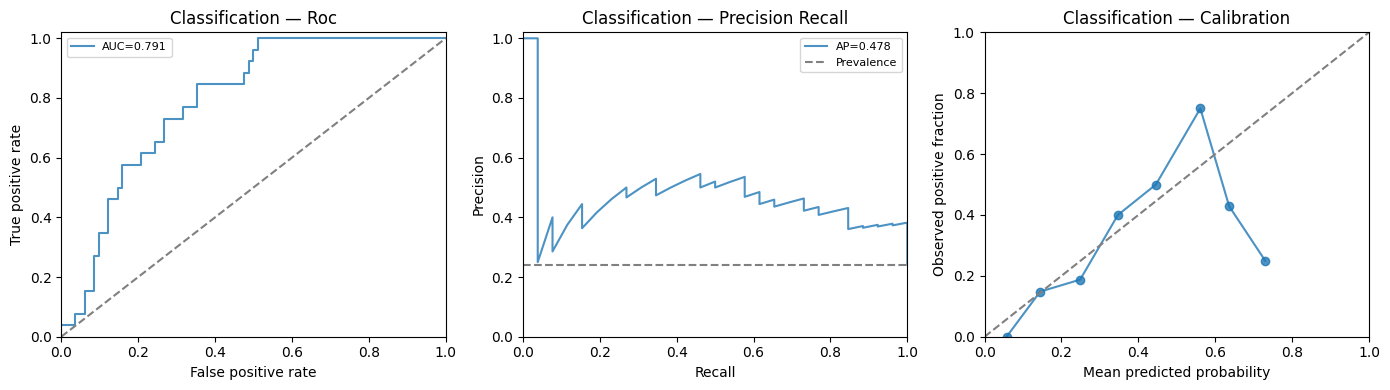

{'selected': 'none',
 'test_indices': [2,
  7,
  8,
  11,
  17,
  22,
  24,
  25,
  27,
  29,
  30,
  36,
  41,
  42,
  54,
  61,
  62,
  71,
  82,
  84,
  94,
  96,
  97,
  98,
  103,
  105,
  107,
  113,
  114,
  116,
  117,
  122,
  123,
  128,
  132,
  141,
  142,
  145,
  150,
  152,
  159,
  164,
  174,
  175,
  178,
  182,
  183,
  186,
  187,
  188,
  189,
  195,
  196,
  197,
  206,
  212,
  218,
  221,
  223,
  226,
  231,
  232,
  240,
  244,
  245,
  246,
  258,
  264,
  265,
  266,
  268,
  269,
  270,
  271,
  272,
  274,
  275,
  276,
  277,
  278,
  280,
  281,
  282,
  285,
  286,
  288,
  289,
  306,
  309,
  310,
  313,
  314,
  318,
  320,
  323,
  327,
  328,
  329,
  331,
  335,
  338,
  339,
  344,
  345,
  347,
  352,
  353,
  359],
 'truth': [1,
  0,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  1,
  0,
  1,
  1,
  0,
  1,
  1,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,

In [11]:
ctx.run('2-4','cls_final')

### 2-5

**문제 (8점)** 사전 지정 비용과 임계값으로 최종평가 오분류 비용을 계산하고 운영 의사결정을 제안하시오. AUC·확률 보정·분류 임계값의 차이, 샘플링에 따른 발생률 변화와 별도 학습 검증 필요성을 설명하시오. 최종평가를 보고 새 임계값을 최적화하지 마시오.

**선택 근거·가정·해석**

비용=FN×지정비용+FP×1이다. 임계값0.5를 사전 고정했으므로 test에서 유리한 값으로 바꾸지 않는다. 운영 임계값·확률 재보정은 별도 학습 검증/OOF에서 사전 결정해야 한다.

In [12]:
ctx.run('2-5','cls_decision')

{'false_negative_cost': 4,
 'false_positive_cost': 1,
 'holdout_cost_at_prespecified_half': 84,
 'decision': 'ROC AUC measures ranking, AP reflects imbalance and Brier reflects probability quality. Resampling alters prevalence: calibrated probabilities or an operating threshold need separate training validation; do not optimize a threshold on final test.',
 'logistic_not_continuous_regression': '0/1 target uses logit mean; no ordinary R2/t/F/normal residual assumptions'}

## 3. 미래 수요와 시간순 검증

timeseries.csv는 공동주택 가격의 별도140일 합성 수요/사용 기록이다. date는 중복 없는 등간격 일자, target은 원 단위 관측량이며 공변량 예측은 사용하지 않는다. 마지막7일은 최종 미래 평가로 봉인한다. 학습의 마지막14일을 두 구간으로 나눠 각각 직전까지 확장 학습하고7일씩 예측한다. 차수 후보(0,0,0)·(1,0,0)를 rolling 평균 RMSE로 선택한다. 비계절 ARIMA를 사용하며 기준은 직전 값 반복이다. 예측구간 신뢰수준95%이고 최적화 최대100회다. 회귀/분류 자료와는 다른 과제다.

### 3-1

**문제 (6점)** 시간 간격·순서·목표·예측 horizon을 확인하고 과거/최종 미래를 나누시오. 학습의 정상성 진단 가설·통계량·p값과 추세·계절성의 한계를 설명하시오. 무작위 CV가 부적절한 이유를 서술하시오.

**선택 근거·가정·해석**

과거에서만 정상성(단위근 귀무) 진단을 수행한다. ADF 비기각은 단위근 확정이 아니며 추세·계절 사양과 작은 표본의 한계를 함께 확인한다.

In [13]:
ctx.run('3-1','ts_design')

{'n': 140,
 'frequency': 'daily',
 'period': 1,
 'train_end': '2024-05-12 00:00:00',
 'test_start': '2024-05-13 00:00:00',
 'horizon': 7,
 'training_adf': {'test_type': 'adf',
  'statistic': -2.4623141851264254,
  'p_value': 0.12491495843886902,
  'reject_h0': False,
  'alpha': 0.05,
  'null_hypothesis': '시계열에 단위근이 존재한다',
  'alternative': 'omnibus',
  'method_used': 'augmented-dickey-fuller',
  'details': {'regression': 'c', 'autolag': 'AIC'},
  'warnings': ['단위근 기각은 모든 형태의 정상성 증명이 아닙니다.'],
  'used_lag': 2,
  'nobs': 130,
  'critical_values': {'1%': -3.4816817173418295,
   '5%': -2.8840418343195267,
   '10%': -2.578770059171598},
  'information_criterion': 229.37410433776353},
 'rule': 'chronological only; transforms and lag selection must use past observations'}

### 3-2

**문제 (6점)** 지정 expanding rolling 검증을 구현하여 후보별 RMSE·MAE·수렴/실패, 각 과거/검증 구간을 제시하고 차수를 선택하시오. 최종 미래값을 차수·전처리 선택에 사용하지 마시오.

**선택 근거·가정·해석**

각 rolling train은 validation보다 앞서고 모든 validation은 최종test보다 앞선다. 후보 적합 실패·미수렴은 기록하고 적격 후보의 평균 RMSE로 선택한다.

In [14]:
ctx.run('3-2','ts_tuning')

{'comparison': {'columns': ['order', 'cv_rmse', 'cv_mae', 'error'],
  'index': [0, 1],
  'data': [[[0, 0, 0], 1.4724331846371532, 1.3458754641533721, None],
   [[1, 0, 0], 0.90531003265281, 0.7253345737391208, None]]},
 'folds': [{'train_indices': [0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15,
    16,
    17,
    18,
    19,
    20,
    21,
    22,
    23,
    24,
    25,
    26,
    27,
    28,
    29,
    30,
    31,
    32,
    33,
    34,
    35,
    36,
    37,
    38,
    39,
    40,
    41,
    42,
    43,
    44,
    45,
    46,
    47,
    48,
    49,
    50,
    51,
    52,
    53,
    54,
    55,
    56,
    57,
    58,
    59,
    60,
    61,
    62,
    63,
    64,
    65,
    66,
    67,
    68,
    69,
    70,
    71,
    72,
    73,
    74,
    75,
    76,
    77,
    78,
    79,
    80,
    81,
    82,
    83,
    84,
    85,
    86,
    87,
    88,
    89,
    90,
    91,
    92,
    93,
    94,
    9

### 3-3

**문제 (6점)** 선택 모형의 학습 AIC·BIC와 초기화 구간을 제외한 잔차 자기상관 진단을 보고하시오. 추정한 AR/MA 자유도를 반영하고 가설·통계량·p값·판정·해석을 제시하시오. 차분이나 우도 정의가 다른 모형의 정보량 단순 비교를 경계하시오.

**선택 근거·가정·해석**

Ljung-Box는 지정 지연까지 자기상관 없음이 귀무이며 AR/MA p+q+P+Q를 자유도에서 차감한다. 초기화 구간을 제외한다. 비기각은 모든 독립성의 증명이 아니며 AIC/BIC는 학습 적합 기준이다.

In [15]:
ctx.run('3-3','ts_diagnostics')

{'diagnostics': {'aic': 264.78899741589373,
  'bic': 273.460044800559,
  'burn': 1,
  'model_df': 1,
  'lag': 4,
  'ljung_box_statistic': 16.486531776069327,
  'ljung_box_p_value': 0.0009011150604124894},
 'train_information': {'aic': 264.78899741589373, 'bic': 273.460044800559},
 'meaning': 'Ljung-Box subtracts p+q+P+Q degrees of freedom and removes initialization. Nonrejection does not prove independence. Compare differencing/families via rolling error; AIC/BIC are not predictive R2.'}

### 3-4

**문제 (6점)** 선택 모형과 지정 naive의 동일 미래7일 RMSE·MAE·R²·MASE를 비교하고 예측·관측·조건부 예측구간을 시각화하시오. MASE의 학습 분모, 음의 보류 R² 가능성, 차수 선택 불확실성을 구간이 모두 반영하지 않는 한계를 설명하시오.

**선택 근거·가정·해석**

동일 미래 horizon에서 선택/naive를 비교한다. MASE 분모는 train의 주기별 차이 절대평균이며0이면 정의하지 않는다. 예측구간은 선택 모형에 조건부이며 차수 선택·모형 오사양 불확실성을 전부 포함하지 않는다.

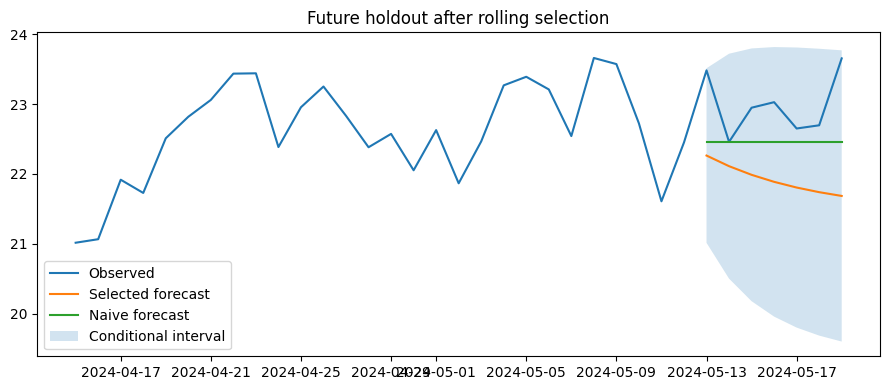

{'test_metrics': {'selected': {'rmse': 1.155324227690136,
   'mae': 1.0630668915839705,
   'r2': -6.9787015983566265},
  'baseline': {'rmse': 0.6758030263896063,
   'mae': 0.5379754545428561,
   'r2': -1.7300130677358223},
  'mase_denominator': 0.5438602457083334,
  'mase': 1.954669237129868},
 'test_indices': [133, 134, 135, 136, 137, 138, 139],
 'truth': [23.4817701178,
  22.4578857978,
  22.9469719938,
  23.0262240742,
  22.6493161703,
  22.6951917933,
  23.6533054147],
 'predictions': [22.262024697008734,
  22.10986041646878,
  21.986199630272626,
  21.885703048628194,
  21.804031540360434,
  21.737658782664752,
  21.683719005408687],
 'baseline_predictions': [22.4492624543,
  22.4492624543,
  22.4492624543,
  22.4492624543,
  22.4492624543,
  22.4492624543,
  22.4492624543],
 'interval_lower': [21.012439747976533,
  20.49966563783465,
  20.176828515254293,
  19.956026219493427,
  19.798852949993368,
  19.684136767002993,
  19.59888324742978],
 'interval_upper': [23.511609646040935

In [16]:
ctx.run('3-4','ts_final')